Sreenidhi S - 24BAD114

[Sreenidhi S - 24BAD114] Loading and preprocessing MNIST dataset...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original shape: Train (60000, 28, 28), Test (10000, 28, 28)
Data type: float32, Range: [0.0, 1.0]
Flattened dimensions: 784


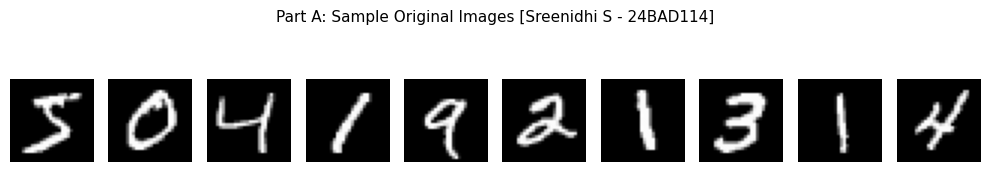

In [1]:
# Ensure the very first line printed in the output matches the required format
print("Sreenidhi S - 24BAD114")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from sklearn.metrics import mean_squared_error

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

STUDENT_ROLL_NO = "24BAD114"
STUDENT_NAME = "Sreenidhi S"
LATENT_DIM = 32  # 784 -> 32 (compression factor ~24.5x)
BATCH_SIZE = 256
EPOCHS = 20

# PART A: DATASET PREPARATION
print(f"\n[{STUDENT_NAME} - {STUDENT_ROLL_NO}] Loading and preprocessing MNIST dataset...")

(X_train, _), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values to [0, 1]
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print(f"Original shape: Train {X_train.shape}, Test {X_test.shape}")
print(f"Data type: {X_train.dtype}, Range: [{X_train.min()}, {X_train.max()}]")

# Reshape into 1D vectors for Dense Autoencoder (28x28 -> 784)
X_train_flat = X_train.reshape((-1, 784))
X_test_flat = X_test.reshape((-1, 784))
print(f"Flattened dimensions: {X_train_flat.shape[1]}")

# Display sample original images
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.axis('off')
plt.suptitle(f"Part A: Sample Original Images [{STUDENT_NAME} - {STUDENT_ROLL_NO}]", fontsize=11)
plt.tight_layout()
plt.show()

In [2]:
# PART B: IMPLEMENTING THE AUTOENCODER MODEL
# 1. Encoder Model
encoder_input = layers.Input(shape=(784,), name="encoder_input")
x = layers.Dense(128, activation='relu', name="enc_dense_1")(encoder_input)
x = layers.Dense(64, activation='relu', name="enc_dense_2")(x)
bottleneck = layers.Dense(LATENT_DIM, activation='relu', name="bottleneck_layer")(x)

encoder = models.Model(encoder_input, bottleneck, name=f"Encoder_{STUDENT_ROLL_NO}")

# 2. Decoder Model
decoder_input = layers.Input(shape=(LATENT_DIM,), name="decoder_input")
y = layers.Dense(64, activation='relu', name="dec_dense_1")(decoder_input)
y = layers.Dense(128, activation='relu', name="dec_dense_2")(y)
decoder_output = layers.Dense(784, activation='sigmoid', name="reconstruction_output")(y)

decoder = models.Model(decoder_input, decoder_output, name=f"Decoder_{STUDENT_ROLL_NO}")

# 3. Complete Autoencoder
autoencoder_input = layers.Input(shape=(784,), name="autoencoder_input")
encoded_repr = encoder(autoencoder_input)
reconstructed_output = decoder(encoded_repr)

autoencoder = models.Model(autoencoder_input, reconstructed_output, name=f"Autoencoder_{STUDENT_ROLL_NO}")

autoencoder.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='mse'
)

print("\n--- Encoder Summary ---")
encoder.summary()
print("\n--- Decoder Summary ---")
decoder.summary()
print("\n--- Full Autoencoder Summary ---")
autoencoder.summary()


--- Encoder Summary ---


Model: "Encoder_24BAD114"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_dense_1 (Dense)             │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_dense_2 (Dense)             │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck_layer (Dense)        │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_24BAD114 (Functional)   │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_24BAD114 (Functional)   │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)


[Sreenidhi S - 24BAD114] Training Autoencoder for 20 epochs...
Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0655 - val_loss: 0.0382
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0314 - val_loss: 0.0261
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0238 - val_loss: 0.0213
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0203 - val_loss: 0.0187
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0183 - val_loss: 0.0169
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0167 - val_loss: 0.0156
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0155 - val_loss: 0.0147
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0146 - val_loss: 0.0139
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0139 - val_loss: 0.0134
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0134 - val_loss: 0.0129
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0

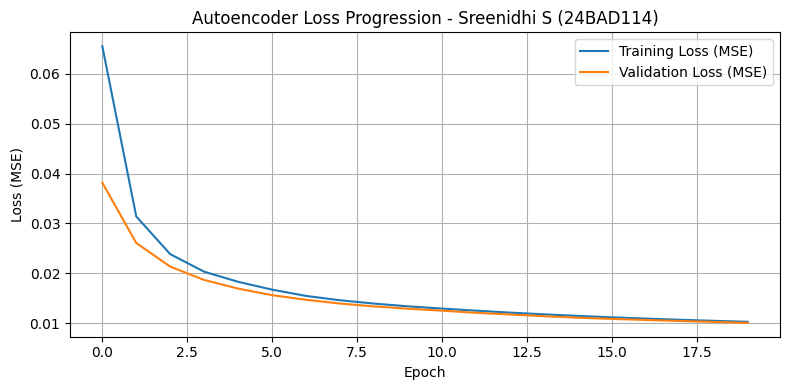

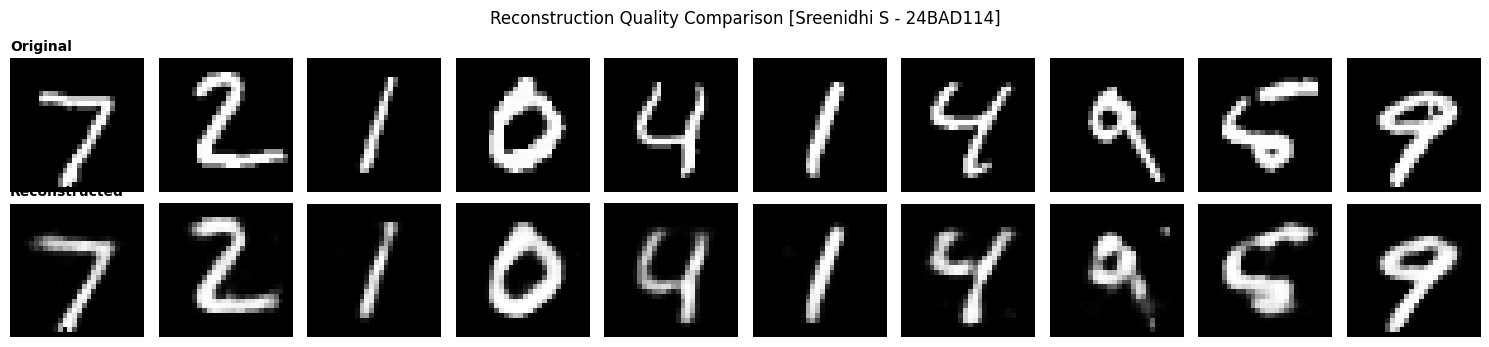

In [3]:
# PART C: MODEL TRAINING AND PERFORMANCE EVALUATION
print(f"\n[{STUDENT_NAME} - {STUDENT_ROLL_NO}] Training Autoencoder for {EPOCHS} epochs...")
history = autoencoder.fit(
    X_train_flat, X_train_flat,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(X_test_flat, X_test_flat),
    verbose=1
)

# Reconstruction error evaluation
reconstructed_test = autoencoder.predict(X_test_flat)
test_mse = mean_squared_error(X_test_flat, reconstructed_test)
print(f"\nTest Reconstruction Mean Squared Error (MSE): {test_mse:.6f}")
# Plot Training and Validation Loss
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training Loss (MSE)', color='tab:blue')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', color='tab:orange')
plt.title(f'Autoencoder Loss Progression - {STUDENT_NAME} ({STUDENT_ROLL_NO})')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
# Compare Original vs Reconstructed Images
n = 10
plt.figure(figsize=(15, 3.5))
for i in range(n):
    # Original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(X_test_flat[i].reshape(28, 28), cmap='gray')
    ax.axis('off')
    if i == 0:
        ax.set_title("Original", loc='left', fontsize=10, fontweight='bold')
    # Reconstructed
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed_test[i].reshape(28, 28), cmap='gray')
    ax.axis('off')
    if i == 0:
        ax.set_title("Reconstructed", loc='left', fontsize=10, fontweight='bold')

plt.suptitle(f"Reconstruction Quality Comparison [{STUDENT_NAME} - {STUDENT_ROLL_NO}]", fontsize=12)
plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

Original Test Data Dimensions: (10000, 784)
Compressed Latent Dimensions:  (10000, 32)
Dimensionality Reduction Ratio: 784 -> 32 (24.5x reduction)


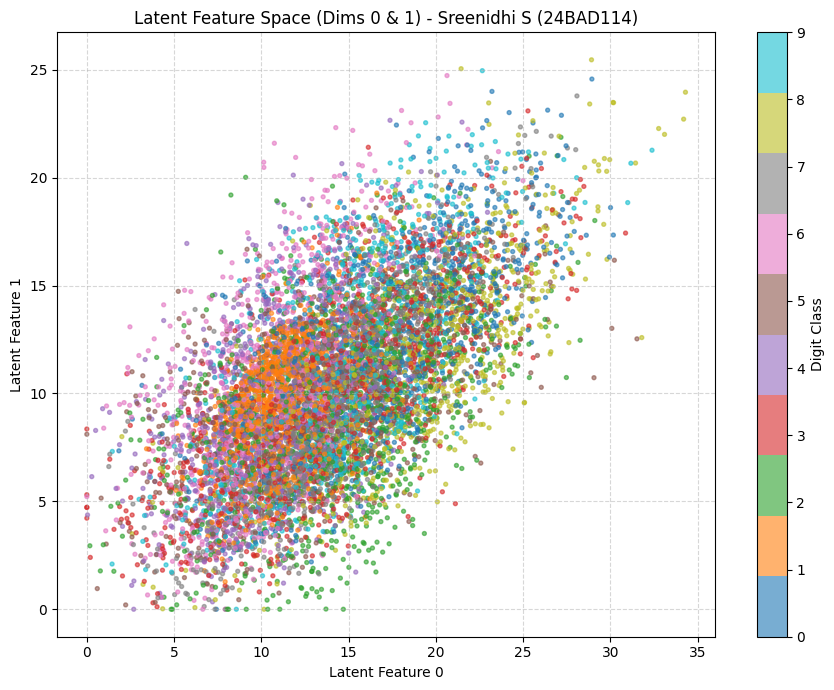

In [4]:
# PART D: DIMENSIONALITY REDUCTION & LATENT FEATURE VISUALIZATION
# Extract latent-space representations using the trained Encoder
encoded_test = encoder.predict(X_test_flat)

print(f"\nOriginal Test Data Dimensions: {X_test_flat.shape}")
print(f"Compressed Latent Dimensions:  {encoded_test.shape}")
print(f"Dimensionality Reduction Ratio: {X_test_flat.shape[1]} -> {encoded_test.shape[1]} ({X_test_flat.shape[1]/encoded_test.shape[1]:.1f}x reduction)")

# 2D Scatter plot of the first two latent dimensions across digit classes
plt.figure(figsize=(9, 7))
scatter = plt.scatter(encoded_test[:, 0], encoded_test[:, 1], c=y_test, cmap='tab10', alpha=0.6, s=8)
plt.colorbar(scatter, label='Digit Class')
plt.title(f'Latent Feature Space (Dims 0 & 1) - {STUDENT_NAME} ({STUDENT_ROLL_NO})')
plt.xlabel('Latent Feature 0')
plt.ylabel('Latent Feature 1')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()